# ch02_4. 실제 데이터로 선형회귀하기

## 참돔 길이로 무게 예측하기

## 개요

- 실제 데이터를 Tensor(텐서, 다차원 배열)로 준비합니다.
- 학습 범위를 벗어난 예측의 한계를 이해합니다.

## 1. 라이브러리와 참돔 데이터 준비

- 입력 $x$: 참돔 길이, 단위는 cm
- 목표값 $y$: 참돔 무게, 단위는 g
- 데이터 수: 56개

한 행이 참돔 한 마리를 의미하도록 입력과 목표값의 shape를 `(56, 1)`로 만듭니다.

In [21]:
import torch
from torch import nn
import matplotlib.pyplot as plt

# 참돔 길이(cm)
fish_length = torch.tensor(
    [
        8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0,
        19.6, 20.0, 21.0, 21.0, 21.0, 21.3, 22.0, 22.0,
        22.0, 22.0, 22.0, 22.5, 22.5, 22.7, 23.0, 23.5,
        24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5,
        27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
        36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0,
        40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5, 44.0,
    ],
    dtype=torch.float32,
).reshape(-1, 1)

# 참돔 무게(g)
fish_weight = torch.tensor(
    [
        5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0,
        85.0, 85.0, 110.0, 115.0, 125.0, 130.0, 120.0, 120.0,
        130.0, 135.0, 110.0, 130.0, 150.0, 145.0, 150.0, 170.0,
        225.0, 145.0, 188.0, 180.0, 197.0, 218.0, 300.0, 260.0,
        265.0, 250.0, 250.0, 300.0, 320.0, 514.0, 556.0, 840.0,
        685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0, 850.0,
        900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0, 1000.0,
    ],
    dtype=torch.float32,
).reshape(-1, 1)

print("길이 shape:", fish_length.shape)
print("무게 shape:", fish_weight.shape)
print("길이 범위:", fish_length.min().item(), "~", fish_length.max().item(), "cm")

길이 shape: torch.Size([56, 1])
무게 shape: torch.Size([56, 1])
길이 범위: 8.399999618530273 ~ 44.0 cm


## 2. 데이터 분포 확인

Scatter Plot(스캐터 플롯, 산점도)은 두 변수의 관계를 점으로 나타냅니다.

길이가 증가할수록 무게도 증가하지만, 점들이 완전한 직선 위에 있지는 않습니다.
선형회귀는 이 데이터의 전체 경향을 하나의 직선으로 표현합니다.

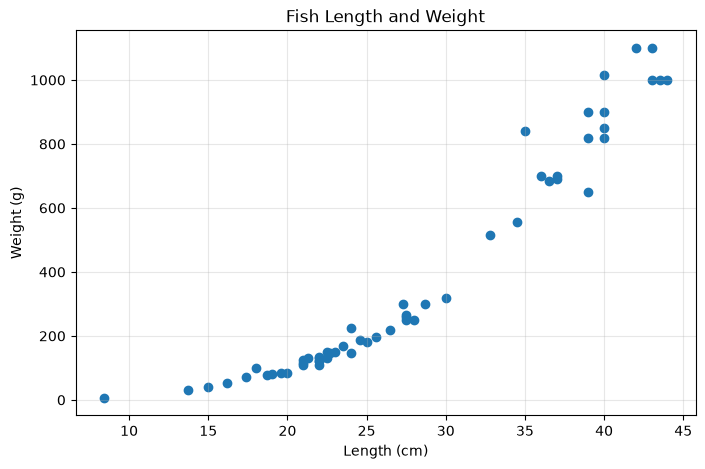

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(fish_length.numpy(), fish_weight.numpy())
plt.xlabel("Length (cm)")
plt.ylabel("Weight (g)")
plt.title("Fish Length and Weight")
plt.grid(alpha=0.3)
plt.show()

## 3. 훈련 데이터와 테스트 데이터 분리

- 훈련 데이터 42개: 가중치와 편향 학습
- 테스트 데이터 14개: 학습에 사용하지 않고 성능 평가
- 분할 비율: 75% 대 25%

`torch.randperm()`은 데이터의 순서를 무작위로 섞은 인덱스를 만듭니다.
`manual_seed()`를 사용하여 다시 실행해도 같은 분할 결과가 나오도록 합니다.

In [23]:
torch.manual_seed(42)

indices = torch.randperm(len(fish_length))

test_indices = indices[:14]
train_indices = indices[14:]

x_train = fish_length[train_indices]
y_train = fish_weight[train_indices]

x_test = fish_length[test_indices]
y_test = fish_weight[test_indices]

print("훈련 데이터:", x_train.shape, y_train.shape)
print("테스트 데이터:", x_test.shape, y_test.shape)

훈련 데이터: torch.Size([42, 1]) torch.Size([42, 1])
테스트 데이터: torch.Size([14, 1]) torch.Size([14, 1])


## 4. 입력값 표준화

참돔 길이를 평균 0, 표준편차 1에 가까운 값으로 바꿉니다.

$$
x_{\mathrm{scaled}}
=
\frac{x-\mu}{\sigma}
$$

- $\mu$: 훈련 데이터 길이의 평균
- $\sigma$: 훈련 데이터 길이의 표준편차
- 테스트 데이터에도 **훈련 데이터에서 계산한 평균과 표준편차**를 사용

테스트 데이터로 평균과 표준편차를 다시 계산하면 평가 정보가 학습 과정에 섞일 수 있습니다.

In [24]:
x_mean = x_train.mean()
x_std = x_train.std()

x_train_scaled = (x_train - x_mean) / x_std
x_test_scaled = (x_test - x_mean) / x_std

print("표준화 전 평균:", x_train.mean().item())
print("표준화 후 평균:", x_train_scaled.mean().item())
print("표준화 후 표준편차:", x_train_scaled.std().item())

표준화 전 평균: 28.4809513092041
표준화 후 평균: 1.0217939205858784e-07
표준화 후 표준편차: 0.9999999403953552


## 5. 선형회귀 모델 학습

이번 모델은 선형 계층 하나뿐이므로 별도의 모델 클래스를 다시 만들지 않고 `nn.Linear(1, 1)`을 바로 사용합니다.

$$
\hat{y}=Wx+b
$$

학습 흐름은 와 같습니다.

$$
\text{순전파}
\rightarrow
\text{손실}
\rightarrow
\text{역전파}
\rightarrow
\text{갱신}
$$

In [25]:
torch.manual_seed(42)

model = nn.Linear(1, 1)
loss_function = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05,)

epochs = 100
loss_history = []

for epoch in range(epochs):
    # 1. 순전파
    prediction = model(x_train_scaled)

    # 2. 손실 계산
    loss = loss_function(prediction, y_train)

    # 3. 이전 기울기 초기화
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치와 편향 갱신
    optimizer.step()

    loss_history.append(loss.item())

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

처음 Loss: 300126.0625
마지막 Loss: 9840.4189453125


## 6. 손실 변화 확인

학습이 진행될수록 MSE Loss(엠에스이 로스, 평균제곱오차 손실)가 감소합니다.

손실이 0이 되지 않는 이유는 실제 참돔 데이터가 완전한 직선 관계가 아니기 때문입니다.

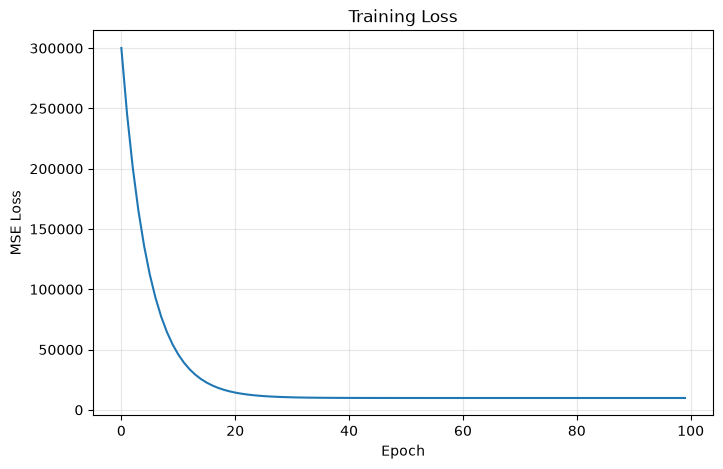

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 7. 실제 단위의 회귀식 확인

모델은 표준화된 길이를 입력받습니다.

$$
\hat{y}
=
W_{\mathrm{scaled}}
\left(
\frac{x-\mu}{\sigma}
\right)
+
b_{\mathrm{scaled}}
$$

이를 cm와 g 단위의 직선으로 바꾸면 다음과 같습니다.

$$
\hat{y}
=
W_{\mathrm{real}}x+b_{\mathrm{real}}
$$

이 변환은 결과를 실제 단위로 해석하기 위한 과정입니다.

In [ ]:
scaled_weight = model.weight.item()
scaled_bias = model.bias.item()

real_weight = scaled_weight / x_std.item()
real_bias = (scaled_bias - scaled_weight * x_mean.item() / x_std.item())

print(f"학습된 회귀식:" f"무게 = {real_weight:.2f} x 길이 {real_bias:+.2f}")
print(f"기울기: {real_weight:.2f} g/cm")
print(f"절편: {real_bias:.2f} g")

학습된 회귀식:무게 = 36.26 × 길이 -618.12
기울기: 36.26 g/cm
절편: -618.12 g


## 8. 훈련 데이터와 테스트 데이터 평가

- 세 가지 지표를 함께 확인합니다.
- 지표단위이상치 민감도주요 사용 목적
- MSE : 실제 단위의 제곱매우 높음모델 학습(손실함수)에 최적화
- RMSE : 실제 데이터와 동일높음큰 오차에 민감하게 반응하며 직관적 단위 확인
- MAE : 실제 데이터와 동일낮음이상치가 많은 데이터에서 강건한 오차 측정
- $R^2$ : 없음 (0~1)-모델의 전체적인 데이터 설명력(상대적 성능) 평가

| 지표 | 의미 | 해석 |
|---|---|---|
| MAE | 오차 절댓값의 평균 | 평균적으로 몇 g 틀리는지 확인 | 
| RMSE | 제곱오차 평균의 제곱근 | 큰 오차에 더 민감 |
| $R^2$ | 실제값 변화의 설명 정도 | 1에 가까울수록 좋음 |

$$ \mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i-\hat{y}_i| $$

$$ \mathrm{RMSE} = \sqrt{ \frac{1}{n} \sum_{i=1}^{n} (y_i-\hat{y}_i)^2 } $$

$$ R^2 = 1- \frac{ \sum (y_i-\hat{y}_i)^2 }{ \sum (y_i-\bar{y})^2 } $$

In [28]:
def regression_metrics(y_true, y_pred):
    error = y_pred - y_true

    mae = error.abs().mean()
    rmse = (error ** 2).mean().sqrt()

    residual_sum = (error ** 2).sum()
    total_sum = ((y_true - y_true.mean()) ** 2).sum()
    r2 = 1 - residual_sum / total_sum

    return mae, rmse, r2


model.eval()

with torch.no_grad():
    train_prediction = model(x_train_scaled)
    test_prediction = model(x_test_scaled)

train_mae, train_rmse, train_r2 = regression_metrics(
    y_train, train_prediction,)

test_mae, test_rmse, test_r2 = regression_metrics(
    y_test,test_prediction,)

print("[훈련 데이터]")
print(f"MAE : {train_mae.item():.2f} g")
print(f"RMSE: {train_rmse.item():.2f} g")
print(f"R²  : {train_r2.item():.4f}")

print()
print("[테스트 데이터]")
print(f"MAE : {test_mae.item():.2f} g")
print(f"RMSE: {test_rmse.item():.2f} g")
print(f"R²  : {test_r2.item():.4f}")

[훈련 데이터]
MAE : 77.94 g
RMSE: 99.20 g
R²  : 0.9240

[테스트 데이터]
MAE : 80.80 g
RMSE: 97.74 g
R²  : 0.8705


## 9. 여러 길이의 무게 예측

25 cm, 35 cm, 40 cm와 함께 50 cm 참돔의 무게를 예측합니다.

50 cm는 학습 데이터의 최대 길이인 44 cm보다 큽니다.
이처럼 학습 범위를 벗어난 값을 예측하는 것을 Extrapolation(엑스트라폴레이션, 외삽)이라고 합니다.

> 선형회귀는 직선을 그대로 연장하므로 값을 계산할 수는 있지만,
> **학습 범위 밖의 예측은 실제 생물의 성장 특성과 다를 수 있어 주의해야 합니다.**

In [ ]:
new_lengths = torch.tensor([[25.0], [35.0], [40.0], [50.0]])

new_lengths_scaled = (new_lengths - x_mean) / x_std

with torch.no_grad():
    new_weights = model(new_lengths_scaled)

for length, weight in zip(new_lengths, new_weights):
    print(f"{length.item():.0f} cm "
          f"→ {weight.item():.1f} g")

25 cm → 288.4 g
35 cm → 650.9 g
40 cm → 832.2 g
50 cm → 1194.8 g


## 10. 데이터와 회귀 직선 확인

- 점: 실제 참돔 데이터
- 선: 모델이 학습한 선형회귀 직선
- 삼각형: 50 cm 예측값

그래프에서 데이터가 직선 주변에 퍼져 있는 정도를 함께 확인합니다.

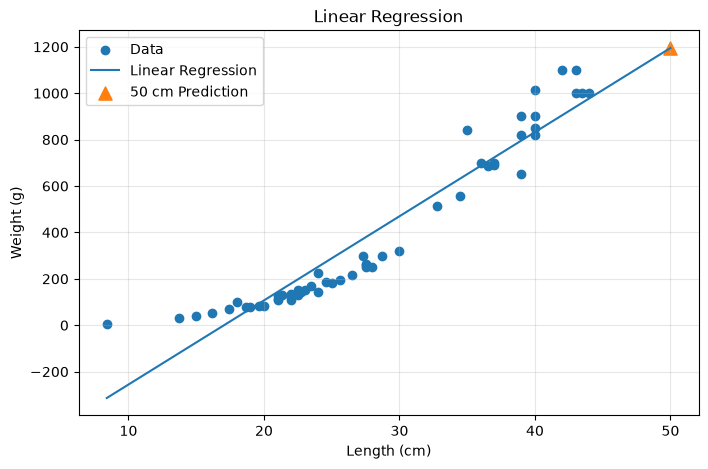

In [ ]:
line_x = torch.linspace(fish_length.min().item(),
    50.0, steps=100,).reshape(-1, 1)

line_x_scaled = (line_x - x_mean) / x_std

with torch.no_grad():
    line_y = model(line_x_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(fish_length.numpy(),fish_weight.numpy(),label="Data",)
plt.plot(line_x.numpy(),line_y.numpy(),label="Linear Regression",)
plt.scatter([50.0],[new_weights[-1].item()], marker="^", 
            s=90, label="50 cm Prediction",)
plt.xlabel("Length (cm)")
plt.ylabel("Weight (g)")
plt.title("Linear Regression")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 12. 핵심 정리

- 실제 데이터는 완전한 직선이 아니므로 Loss가 0이 되지 않을 수 있습니다.
- MAE와 RMSE는 오차를 g 단위로 해석하게 해줍니다.
- 학습 범위를 벗어난 외삽 결과는 신중하게 해석해야 합니다.